
Processing region: Amazon
Regime points: N=56 (High VPD & Low SM).  Medians: SM=0.3736, VPD=0.7595
Saved figure (no legend): E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Amazon.png
Saved legend: E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Amazon_legend.png


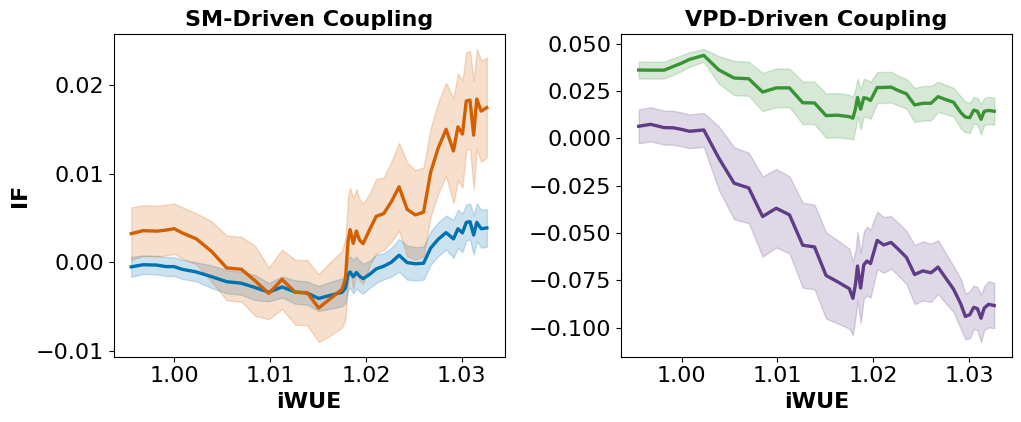


Processing region: Congo
Regime points: N=71 (High VPD & Low SM).  Medians: SM=0.3336, VPD=0.5303
Saved figure (no legend): E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Congo.png
Saved legend: E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Congo_legend.png


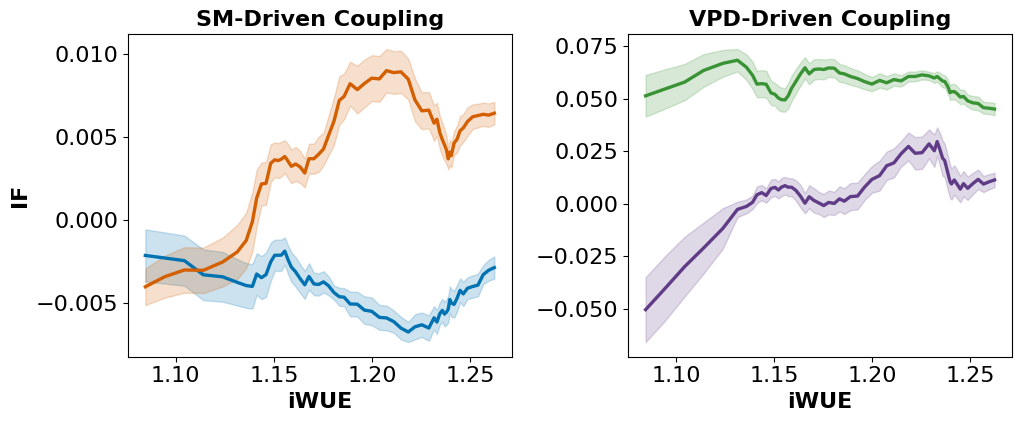


Processing region: China
Regime points: N=66 (High VPD & Low SM).  Medians: SM=0.4175, VPD=0.5361
Saved figure (no legend): E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\China.png
Saved legend: E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\China_legend.png


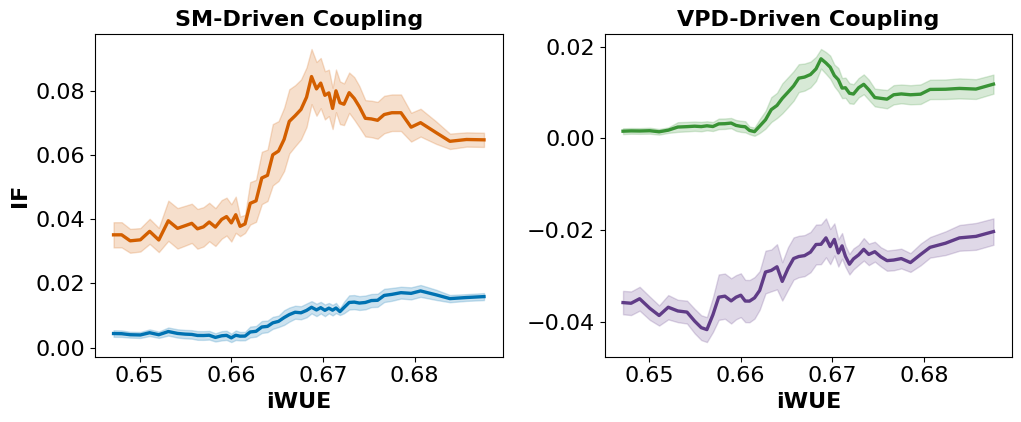


Processing region: Australia
Regime points: N=56 (High VPD & Low SM).  Medians: SM=0.3097, VPD=0.5399
Saved figure (no legend): E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Australia.png
Saved legend: E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Australia_legend.png


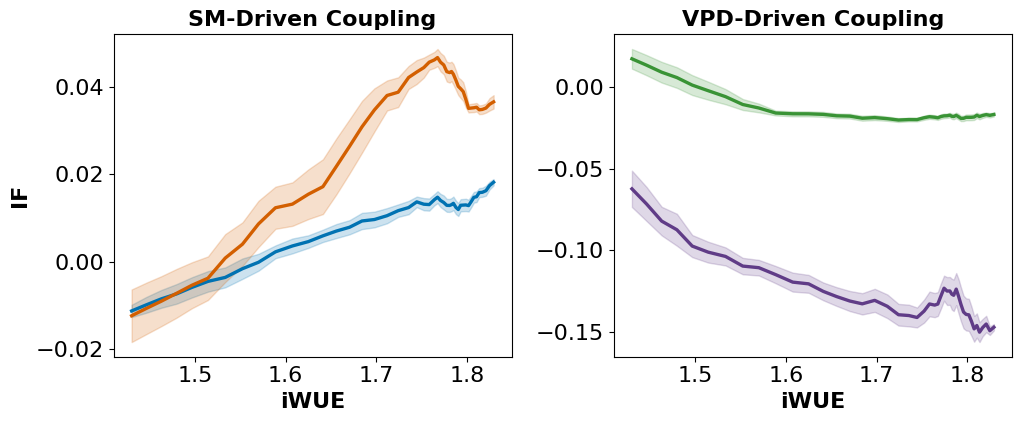


Processing region: Taiga
Regime points: N=63 (High VPD & Low SM).  Medians: SM=0.3176, VPD=0.2859
Saved figure (no legend): E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Taiga.png
Saved legend: E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures\Taiga_legend.png


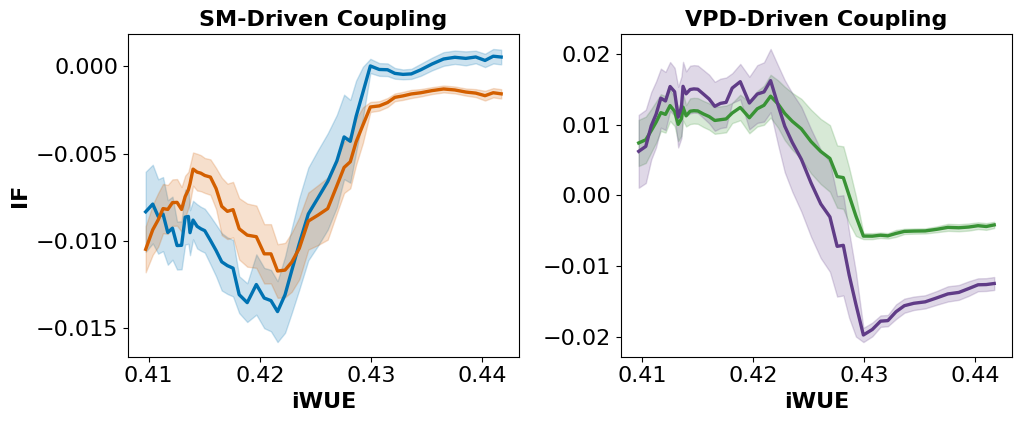


Done: All regional analysis iterations are complete.


In [4]:
import os
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt


# ----------------------------
# 0) Global styling 
# ----------------------------
plt.rcParams.update({
    "font.size": 16,               # Base font size (increased from 13)
    "axes.titlesize": 16,          # Subplot title font size (increased from 15)
    "axes.labelsize": 16,          # Axis labels font size (increased from 14)
    "xtick.labelsize": 16,         # X-tick font size (increased from 12)
    "ytick.labelsize": 16,         # Y-tick font size (increased from 12)
    "legend.fontsize": 14,         # Legend font size (increased from 12)

    "font.weight": "normal",
    "axes.titleweight": "bold",    # Made titles bold for cleaner structure
    "axes.labelweight": "bold",    # Made axis labels bold for clear emphasis
})


# ----------------------------
# 1) User settings
# ----------------------------
W = 36
k = 12
start_date = "2004-01-01"

# Define the sequence of regions
REGIONS = ["Amazon", "Congo", "China", "Australia", "Taiga"]

# --- base directories ---
BASE_IN_DIR = r"E:\CAZ-Again\WUE_under_LowSM_highVPD"
OUT_DIR     = r"E:\CAZ-Again\\WUE_under_LowSM_highVPD\Figures"
DPI = 400


# ----------------------------
# 2) Helpers
# ----------------------------
def load_1d_from_mat(path, preferred_key=None):
    """Load a 1D vector from a .mat file. If preferred_key is provided, use it."""
    mat = sio.loadmat(path)

    # 1) Try the preferred key first (deterministic)
    if preferred_key is not None and preferred_key in mat:
        v = np.squeeze(mat[preferred_key])
        if v.ndim == 1:
            return v

    # 2) Fallback: scan and return the first "reasonable" 1D vector
    for k0, v0 in mat.items():
        if k0.startswith("__"):
            continue
        if isinstance(v0, np.ndarray) and v0.size > 1:
            vv = np.squeeze(v0)
            if vv.ndim == 1 and vv.size >= 50:
                return vv

    raise ValueError(f"Could not find a suitable 1D vector in {path}.")


def smooth_mean_se(y_sorted, k):
    """Rolling mean and SE (std/sqrt(k)) in iWUE-sorted space."""
    s = pd.Series(y_sorted)
    mean = s.rolling(k, center=True, min_periods=k).mean().values
    std = s.rolling(k, center=True, min_periods=k).std(ddof=1).values
    se = std / np.sqrt(k)
    return mean, se


def save_legend_only(handles, labels, out_path, dpi=400, ncol=4, fontsize=12):
    """
    Save a separate legend-only PNG.
    - Creates a tiny figure, draws legend, then resizes/crops via bbox_inches='tight'.
    """
    fig_leg = plt.figure(figsize=(1, 1), dpi=dpi)
    fig_leg.legend(
        handles,
        labels,
        loc="center",
        ncol=ncol,
        frameon=False,
        fontsize=fontsize,
        handlelength=2.6,
        columnspacing=1.6,
        handletextpad=0.6,
        borderaxespad=0.0,
    )
    fig_leg.canvas.draw()
    fig_leg.savefig(out_path, dpi=dpi, bbox_inches="tight", transparent=True)
    plt.close(fig_leg)


# ----------------------------
# Loop through each individual target region
# ----------------------------
for REGION in REGIONS:
    print("\n" + "="*50)
    print(f"Processing region: {REGION}")
    print("="*50)

    # Dynamically build path mappings matching file system arrays
    PATH_SM_LAI  = os.path.join(BASE_IN_DIR, f"{REGION}_m_sm_lai.mat")
    PATH_SM_GPP  = os.path.join(BASE_IN_DIR, f"{REGION}_m_sm_gpp.mat")
    PATH_VPD_LAI = os.path.join(BASE_IN_DIR, f"{REGION}_m_vpd_lai.mat")
    PATH_VPD_GPP = os.path.join(BASE_IN_DIR, f"{REGION}_m_vpd_gpp.mat")
    PATH_IWUE    = os.path.join(BASE_IN_DIR, f"{REGION}_WUE.mat")
    
    # Raw drivers track lower-case suffixes for Australia/Taiga/Amazon compatibility handles
    PATH_VPD_RAW = os.path.join(BASE_IN_DIR, f"VPD_{REGION.lower()}_raw_TS.mat")
    PATH_SM_RAW  = os.path.join(BASE_IN_DIR, f"SM_{REGION.lower()}_raw_TS.mat")

    OUT_NAME_FIG = f"{REGION}.png"         # main figure (NO legend)
    OUT_NAME_LEG = f"{REGION}_legend.png"  # legend-only figure

    # Verify presence of mandatory target layers before parsing matrix arrays
    if not os.path.exists(PATH_SM_LAI):
        print(f"Skipping {REGION}: File not found ({PATH_SM_LAI})")
        continue

    # ----------------------------
    # 3) Load data
    # ----------------------------
    sm_lai  = load_1d_from_mat(PATH_SM_LAI,  preferred_key=f"{REGION}_m_sm_lai")
    sm_gpp  = load_1d_from_mat(PATH_SM_GPP,  preferred_key=f"{REGION}_m_sm_gpp")
    vpd_lai = load_1d_from_mat(PATH_VPD_LAI, preferred_key=f"{REGION}_m_vpd_lai")
    vpd_gpp = load_1d_from_mat(PATH_VPD_GPP, preferred_key=f"{REGION}_m_vpd_gpp")
    iwue    = load_1d_from_mat(PATH_IWUE,    preferred_key=f"{REGION}_WUE")

    vpd_raw = load_1d_from_mat(PATH_VPD_RAW)
    sm_raw  = load_1d_from_mat(PATH_SM_RAW)

    n = len(iwue)
    for arr, name in [
        (sm_lai, "SM→LAI"), (sm_gpp, "SM→GPP"),
        (vpd_lai, "VPD→LAI"), (vpd_gpp, "VPD→GPP"),
        (vpd_raw, "VPD_raw"), (sm_raw, "SM_raw"),
    ]:
        if len(arr) != n:
            raise ValueError(f"Length mismatch: {name} has {len(arr)} but iWUE has {n}.")

    # ----------------------------
    # 4) Build dataframe + rolling means
    # ----------------------------
    dates = pd.date_range(start_date, periods=n, freq="MS")

    df = (
        pd.DataFrame(
            {
                "SM→LAI": sm_lai,
                "SM→GPP": sm_gpp,
                "VPD→LAI": vpd_lai,
                "VPD→GPP": vpd_gpp,
                "iWUE": iwue,
                "VPD_raw": vpd_raw,
                "SM_raw": sm_raw,
            },
            index=dates,
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    df["iWUE_win"] = df["iWUE"].rolling(W, min_periods=W).mean()
    df["VPD_win"]  = df["VPD_raw"].rolling(W, min_periods=W).mean()
    df["SM_win"]   = df["SM_raw"].rolling(W, min_periods=W).mean()
    df = df.dropna(subset=["iWUE_win", "VPD_win", "SM_win"])

    # ----------------------------
    # 5) Define regime: High VPD & Low SM (median splits)
    # ----------------------------
    sm_med  = float(np.median(df["SM_win"].values))
    vpd_med = float(np.median(df["VPD_win"].values))
    mask_reg = (df["SM_win"].values <= sm_med) & (df["VPD_win"].values > vpd_med)

    sub = df.loc[mask_reg].copy()
    N_reg = len(sub)
    if N_reg < k:
        raise ValueError(f"Regime sample size N={N_reg} is smaller than smoother k={k} for {REGION}. Reduce k.")

    print(f"Regime points: N={N_reg} (High VPD & Low SM).  Medians: SM={sm_med:.4g}, VPD={vpd_med:.4g}")

    # ----------------------------
    # 6) Sort by iWUE_win (low→high)
    # ----------------------------
    x = sub["iWUE_win"].values
    order = np.argsort(x)
    x_sorted = x[order]
    x_center = pd.Series(x_sorted).rolling(k, center=True, min_periods=k).mean().values

    # Custom colors
    colors = {
        "SM→LAI":  "#0072b2",
        "SM→GPP":  "#d35f00",
        "VPD→LAI": "#399335",
        "VPD→GPP": "#603c87",
    }

    # ----------------------------
    # 7) Plot: grouped by source (SM vs VPD)
    #      Save FIGURE and LEGEND separately
    # ----------------------------
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), sharex=True)

    # Left: SM-driven
    for c in ["SM→LAI", "SM→GPP"]:
        y_sorted = sub[c].values[order]
        y_mean, y_se = smooth_mean_se(y_sorted, k)
        msk = np.isfinite(x_center) & np.isfinite(y_mean) & np.isfinite(y_se)

        axes[0].plot(x_center[msk], y_mean[msk], lw=2.4, color=colors[c], label=c)
        axes[0].fill_between(
            x_center[msk],
            (y_mean - y_se)[msk],
            (y_mean + y_se)[msk],
            alpha=0.20,
            color=colors[c],
        )

    axes[0].set_title("SM-Driven Coupling")
    axes[0].set_xlabel("iWUE")
    axes[0].set_ylabel("IF")

    # Right: VPD-driven
    for c in ["VPD→LAI", "VPD→GPP"]:
        y_sorted = sub[c].values[order]
        y_mean, y_se = smooth_mean_se(y_sorted, k)
        msk = np.isfinite(x_center) & np.isfinite(y_mean) & np.isfinite(y_se)

        axes[1].plot(x_center[msk], y_mean[msk], lw=2.4, color=colors[c], label=c)
        axes[1].fill_between(
            x_center[msk],
            (y_mean - y_se)[msk],
            (y_mean + y_se)[msk],
            alpha=0.20,
            color=colors[c],
        )

    axes[1].set_title("VPD-Driven Coupling")
    axes[1].set_xlabel("iWUE")
    axes[1].set_ylabel("")  # remove y-axis label text on right panel

    # ---- Collect legend handles/labels (ordered) and save legend-only file
    label_to_handle = {}
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for hh, ll in zip(h, l):
            label_to_handle[ll] = hh

    legend_labels = ["SM→LAI", "SM→GPP", "VPD→LAI", "VPD→GPP"]
    legend_handles = [label_to_handle[lbl] for lbl in legend_labels if lbl in label_to_handle]

    os.makedirs(OUT_DIR, exist_ok=True)
    out_path_fig = os.path.join(OUT_DIR, OUT_NAME_FIG)
    out_path_leg = os.path.join(OUT_DIR, OUT_NAME_LEG)

    # ---- Save MAIN figure WITHOUT legend
    plt.tight_layout()
    fig.savefig(out_path_fig, dpi=DPI, bbox_inches="tight")
    print(f"Saved figure (no legend): {out_path_fig}")

    # ---- Save LEGEND-only figure
    save_legend_only(
        legend_handles,
        legend_labels[:len(legend_handles)],
        out_path_leg,
        dpi=DPI,
        ncol=4,
        fontsize=plt.rcParams["legend.fontsize"],
    )
    print(f"Saved legend: {out_path_leg}")

    plt.show()
    plt.close(fig)

print("\nDone: All regional analysis iterations are complete.")


Processing region: Amazon
Regime points: N=56 (High VPD & Low SM).  Medians: SM=0.3736, VPD=0.7595
Saved figure (no legend): E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Amazon.png
Saved legend: E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Amazon_legend.png


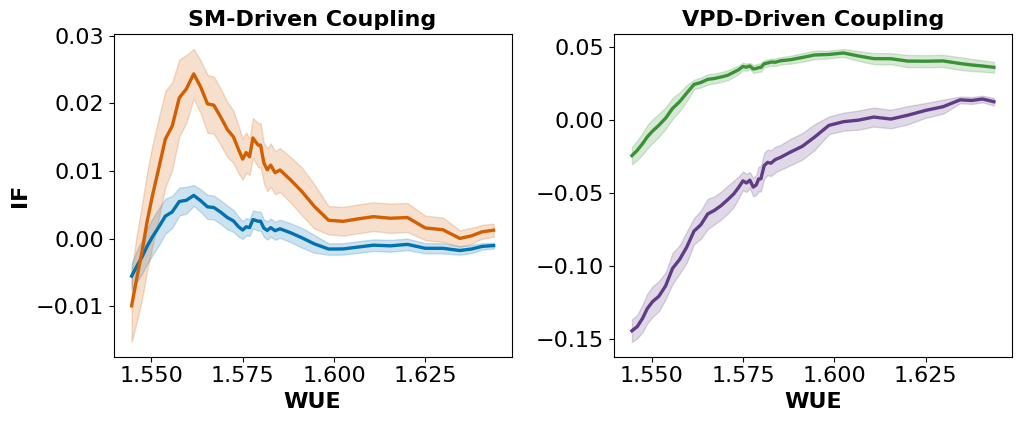


Processing region: Congo
Regime points: N=71 (High VPD & Low SM).  Medians: SM=0.3336, VPD=0.5303
Saved figure (no legend): E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Congo.png
Saved legend: E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Congo_legend.png


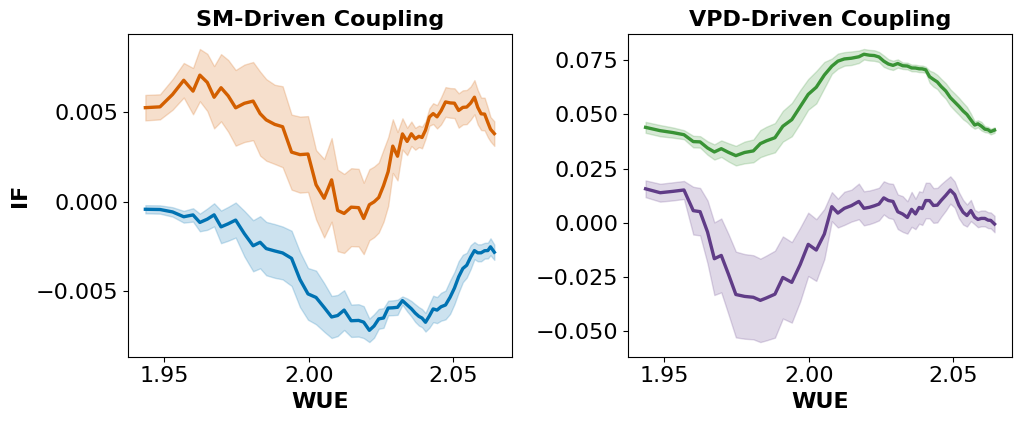


Processing region: China
Regime points: N=66 (High VPD & Low SM).  Medians: SM=0.4175, VPD=0.5361
Saved figure (no legend): E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\China.png
Saved legend: E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\China_legend.png


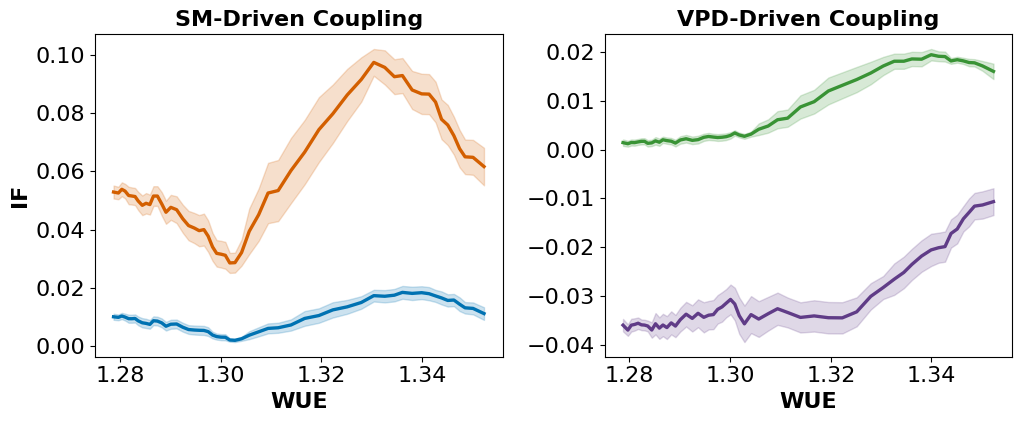


Processing region: Australia
Regime points: N=56 (High VPD & Low SM).  Medians: SM=0.3097, VPD=0.5399
Saved figure (no legend): E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Australia.png
Saved legend: E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Australia_legend.png


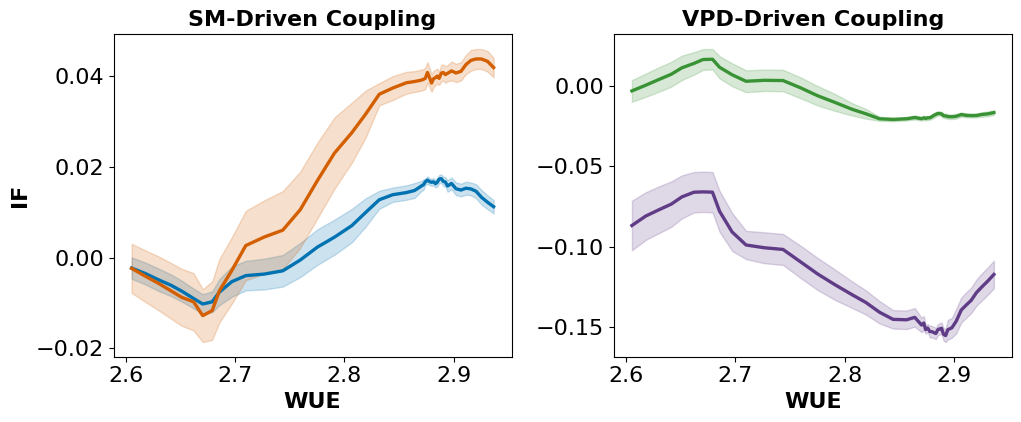


Processing region: Taiga
Regime points: N=63 (High VPD & Low SM).  Medians: SM=0.3176, VPD=0.2859
Saved figure (no legend): E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Taiga.png
Saved legend: E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic\Taiga_legend.png


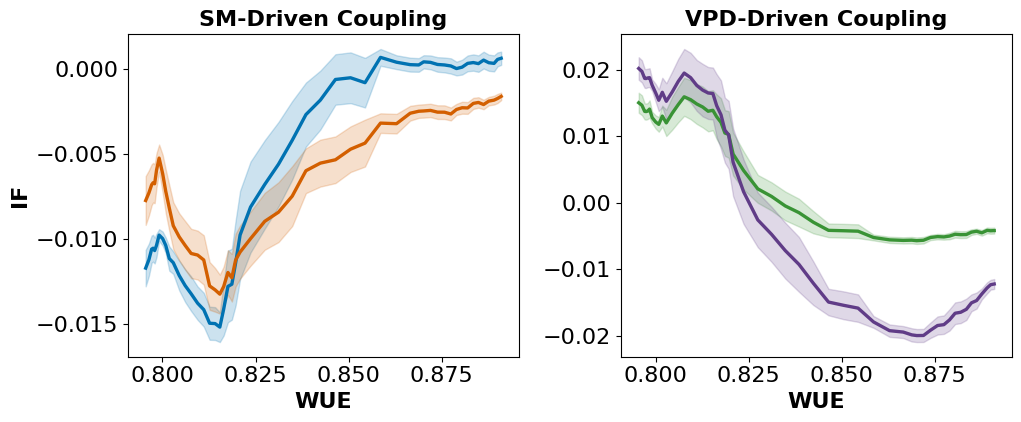


Done: All regional analysis iterations are complete.


In [5]:
import os
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt


# ----------------------------
# 0) Global styling
# ----------------------------
plt.rcParams.update({
    "font.size": 16,               # Base font size (increased from 13)
    "axes.titlesize": 16,          # Subplot title font size (increased from 15)
    "axes.labelsize": 16,          # Axis labels font size (increased from 14)
    "xtick.labelsize": 16,         # X-tick font size (increased from 12)
    "ytick.labelsize": 16,         # Y-tick font size (increased from 12)
    "legend.fontsize": 14,         # Legend font size (increased from 12)

    "font.weight": "normal",
    "axes.titleweight": "bold",    # Made titles bold for cleaner structure
    "axes.labelweight": "bold",    # Made axis labels bold for clear emphasis
})


# ----------------------------
# 1) User settings
# ----------------------------
W = 36
k = 12
start_date = "2004-01-01"

# Define the sequence of regions
REGIONS = ["Amazon", "Congo", "China", "Australia", "Taiga"]

# --- base directories ---
BASE_IN_DIR = r"E:\CAZ-Again\WUE_under_LowSM_highVPD"
OUT_DIR     = r"E:\CAZ-Again\WUE_under_LowSM_highVPD\Intrinsic"
DPI = 400


# ----------------------------
# 2) Helpers
# ----------------------------
def load_1d_from_mat(path, preferred_key=None):
    """Load a 1D vector from a .mat file. If preferred_key is provided, use it."""
    mat = sio.loadmat(path)

    # 1) Try the preferred key first (deterministic)
    if preferred_key is not None and preferred_key in mat:
        v = np.squeeze(mat[preferred_key])
        if v.ndim == 1:
            return v

    # 2) Fallback: scan and return the first "reasonable" 1D vector
    for k0, v0 in mat.items():
        if k0.startswith("__"):
            continue
        if isinstance(v0, np.ndarray) and v0.size > 1:
            vv = np.squeeze(v0)
            if vv.ndim == 1 and vv.size >= 50:
                return vv

    raise ValueError(f"Could not find a suitable 1D vector in {path}.")


def smooth_mean_se(y_sorted, k):
    """Rolling mean and SE (std/sqrt(k)) in iWUE-sorted space."""
    s = pd.Series(y_sorted)
    mean = s.rolling(k, center=True, min_periods=k).mean().values
    std = s.rolling(k, center=True, min_periods=k).std(ddof=1).values
    se = std / np.sqrt(k)
    return mean, se


def save_legend_only(handles, labels, out_path, dpi=400, ncol=4, fontsize=12):
    """
    Save a separate legend-only PNG.
    - Creates a tiny figure, draws legend, then resizes/crops via bbox_inches='tight'.
    """
    fig_leg = plt.figure(figsize=(1, 1), dpi=dpi)
    fig_leg.legend(
        handles,
        labels,
        loc="center",
        ncol=ncol,
        frameon=False,
        fontsize=fontsize,
        handlelength=2.6,
        columnspacing=1.6,
        handletextpad=0.6,
        borderaxespad=0.0,
    )
    fig_leg.canvas.draw()
    fig_leg.savefig(out_path, dpi=dpi, bbox_inches="tight", transparent=True)
    plt.close(fig_leg)


# ----------------------------
# Loop through each individual target region
# ----------------------------
for REGION in REGIONS:
    print("\n" + "="*50)
    print(f"Processing region: {REGION}")
    print("="*50)

    # Dynamically build path mappings matching file system arrays
    PATH_SM_LAI  = os.path.join(BASE_IN_DIR, f"{REGION}_m_sm_lai.mat")
    PATH_SM_GPP  = os.path.join(BASE_IN_DIR, f"{REGION}_m_sm_gpp.mat")
    PATH_VPD_LAI = os.path.join(BASE_IN_DIR, f"{REGION}_m_vpd_lai.mat")
    PATH_VPD_GPP = os.path.join(BASE_IN_DIR, f"{REGION}_m_vpd_gpp.mat")
    PATH_IWUE    = os.path.join(BASE_IN_DIR, f"WUE_intrinsic_{REGION}.mat")

    # Raw drivers track lower-case suffixes for Australia/Taiga/Amazon compatibility handles
    PATH_VPD_RAW = os.path.join(BASE_IN_DIR, f"VPD_{REGION.lower()}_raw_TS.mat")
    PATH_SM_RAW  = os.path.join(BASE_IN_DIR, f"SM_{REGION.lower()}_raw_TS.mat")

    OUT_NAME_FIG = f"{REGION}.png"         # main figure (NO legend)
    OUT_NAME_LEG = f"{REGION}_legend.png"  # legend-only figure

    # Verify presence of mandatory target layers before parsing matrix arrays
    if not os.path.exists(PATH_SM_LAI):
        print(f"Skipping {REGION}: File not found ({PATH_SM_LAI})")
        continue

    # ----------------------------
    # 3) Load data
    # ----------------------------
    sm_lai  = load_1d_from_mat(PATH_SM_LAI,  preferred_key=f"{REGION}_m_sm_lai")
    sm_gpp  = load_1d_from_mat(PATH_SM_GPP,  preferred_key=f"{REGION}_m_sm_gpp")
    vpd_lai = load_1d_from_mat(PATH_VPD_LAI, preferred_key=f"{REGION}_m_vpd_lai")
    vpd_gpp = load_1d_from_mat(PATH_VPD_GPP, preferred_key=f"{REGION}_m_vpd_gpp")
    iwue    = load_1d_from_mat(PATH_IWUE,    preferred_key=f"WUE_intrinsic_{REGION}")

    vpd_raw = load_1d_from_mat(PATH_VPD_RAW)
    sm_raw  = load_1d_from_mat(PATH_SM_RAW)

    n = len(iwue)
    for arr, name in [
        (sm_lai, "SM→LAI"), (sm_gpp, "SM→GPP"),
        (vpd_lai, "VPD→LAI"), (vpd_gpp, "VPD→GPP"),
        (vpd_raw, "VPD_raw"), (sm_raw, "SM_raw"),
    ]:
        if len(arr) != n:
            raise ValueError(f"Length mismatch: {name} has {len(arr)} but iWUE has {n}.")

    # ----------------------------
    # 4) Build dataframe + rolling means
    # ----------------------------
    dates = pd.date_range(start_date, periods=n, freq="MS")

    df = (
        pd.DataFrame(
            {
                "SM→LAI": sm_lai,
                "SM→GPP": sm_gpp,
                "VPD→LAI": vpd_lai,
                "VPD→GPP": vpd_gpp,
                "iWUE": iwue,
                "VPD_raw": vpd_raw,
                "SM_raw": sm_raw,
            },
            index=dates,
        )
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    df["iWUE_win"] = df["iWUE"].rolling(W, min_periods=W).mean()
    df["VPD_win"]  = df["VPD_raw"].rolling(W, min_periods=W).mean()
    df["SM_win"]   = df["SM_raw"].rolling(W, min_periods=W).mean()
    df = df.dropna(subset=["iWUE_win", "VPD_win", "SM_win"])

    # ----------------------------
    # 5) Define regime: High VPD & Low SM (median splits)
    # ----------------------------
    sm_med  = float(np.median(df["SM_win"].values))
    vpd_med = float(np.median(df["VPD_win"].values))
    mask_reg = (df["SM_win"].values <= sm_med) & (df["VPD_win"].values > vpd_med)

    sub = df.loc[mask_reg].copy()
    N_reg = len(sub)
    if N_reg < k:
        raise ValueError(f"Regime sample size N={N_reg} is smaller than smoother k={k} for {REGION}. Reduce k.")

    print(f"Regime points: N={N_reg} (High VPD & Low SM).  Medians: SM={sm_med:.4g}, VPD={vpd_med:.4g}")

    # ----------------------------
    # 6) Sort by iWUE_win (low→high)
    # ----------------------------
    x = sub["iWUE_win"].values
    order = np.argsort(x)
    x_sorted = x[order]
    x_center = pd.Series(x_sorted).rolling(k, center=True, min_periods=k).mean().values

    # Custom colors
    colors = {
        "SM→LAI":  "#0072b2",
        "SM→GPP":  "#d35f00",
        "VPD→LAI": "#399335",
        "VPD→GPP": "#603c87",
    }

    # ----------------------------
    # 7) Plot: grouped by source (SM vs VPD)
    #      Save FIGURE and LEGEND separately
    # ----------------------------
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), sharex=True)

    # Left: SM-driven
    for c in ["SM→LAI", "SM→GPP"]:
        y_sorted = sub[c].values[order]
        y_mean, y_se = smooth_mean_se(y_sorted, k)
        msk = np.isfinite(x_center) & np.isfinite(y_mean) & np.isfinite(y_se)

        axes[0].plot(x_center[msk], y_mean[msk], lw=2.4, color=colors[c], label=c)
        axes[0].fill_between(
            x_center[msk],
            (y_mean - y_se)[msk],
            (y_mean + y_se)[msk],
            alpha=0.20,
            color=colors[c],
        )

    axes[0].set_title("SM-Driven Coupling")
    axes[0].set_xlabel("WUE")
    axes[0].set_ylabel("IF")

    # Right: VPD-driven
    for c in ["VPD→LAI", "VPD→GPP"]:
        y_sorted = sub[c].values[order]
        y_mean, y_se = smooth_mean_se(y_sorted, k)
        msk = np.isfinite(x_center) & np.isfinite(y_mean) & np.isfinite(y_se)

        axes[1].plot(x_center[msk], y_mean[msk], lw=2.4, color=colors[c], label=c)
        axes[1].fill_between(
            x_center[msk],
            (y_mean - y_se)[msk],
            (y_mean + y_se)[msk],
            alpha=0.20,
            color=colors[c],
        )

    axes[1].set_title("VPD-Driven Coupling")
    axes[1].set_xlabel("WUE")
    axes[1].set_ylabel("")  # remove y-axis label text on right panel

    # ---- Collect legend handles/labels (ordered) and save legend-only file
    label_to_handle = {}
    for ax in axes:
        h, l = ax.get_legend_handles_labels()
        for hh, ll in zip(h, l):
            label_to_handle[ll] = hh

    legend_labels = ["SM→LAI", "SM→GPP", "VPD→LAI", "VPD→GPP"]
    legend_handles = [label_to_handle[lbl] for lbl in legend_labels if lbl in label_to_handle]

    os.makedirs(OUT_DIR, exist_ok=True)
    out_path_fig = os.path.join(OUT_DIR, OUT_NAME_FIG)
    out_path_leg = os.path.join(OUT_DIR, OUT_NAME_LEG)

    # ---- Save MAIN figure WITHOUT legend
    plt.tight_layout()
    fig.savefig(out_path_fig, dpi=DPI, bbox_inches="tight")
    print(f"Saved figure (no legend): {out_path_fig}")

    # ---- Save LEGEND-only figure
    save_legend_only(
        legend_handles,
        legend_labels[:len(legend_handles)],
        out_path_leg,
        dpi=DPI,
        ncol=4,
        fontsize=plt.rcParams["legend.fontsize"],
    )
    print(f"Saved legend: {out_path_leg}")

    plt.show()
    plt.close(fig)

print("\nDone: All regional analysis iterations are complete.")
